# CircuitCoach AI — evaluation, export and publishing

Runs on Kaggle (GPU T4, Internet on) with two inputs attached: the **ElectroCom61** dataset and the output of the **circuitcoach-training** notebook (YOLO26n run v2). Add a Kaggle secret `HF_TOKEN` (write token) for the publishing cells.

Run the cells from top to bottom.

## 1. Setup

In [ ]:
%pip install -q ultralytics==8.4.215 huggingface_hub onnx onnxslim onnxruntime

Note: you may need to restart the kernel to use updated packages.


## 2. Rebuild the clean dataset
The split is deterministic, so this reproduces exactly the split used for training (train 1569 | val 322 | test 230).

In [ ]:
%%writefile /kaggle/working/prepare_dataset.py
"""
CircuitCoach AI - dataset preparation for ElectroCom61 (YOLO format).

What it does
1. Merges the original train/valid/test splits into one pool.
2. Checks every image (can it be opened?) and every label line
   (5 numbers, valid class id, box inside the image). Bad lines are dropped;
   polygon lines are converted to boxes; corrupt images are dropped.
3. Finds exact duplicates (same file bytes) and near-duplicates
   (64-bit difference hash), plus Roboflow copies of the same source photo.
4. Re-splits 75/15/10 by duplicate GROUP, so near-identical photos never
   end up on both sides of the train/test line. The split is stratified so
   rare classes still appear in val and test where possible.
5. Writes a clean YOLO dataset, data.yaml, audit.json and per_class_counts.csv.

Usage (Kaggle):
    python prepare_dataset.py                       # finds the dataset by itself
    python prepare_dataset.py --near-dup-bits 4     # stricter near-duplicate match
"""

import argparse
import csv
import hashlib
import json
import random
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import yaml
from PIL import Image

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
ORIG_SPLITS = ["train", "valid", "val", "test"]


# ---------------------------------------------------------------- helpers
def find_raw_root(search_root: Path) -> Path:
    yamls = sorted(search_root.rglob("data.yaml"))
    if not yamls:
        raise SystemExit(f"[error] no data.yaml found under {search_root}")
    return yamls[0].parent


def dhash64(path: Path) -> int:
    """64-bit difference hash: shrink to 9x8 grey, compare neighbours."""
    with Image.open(path) as im:
        g = im.convert("L").resize((9, 8), Image.Resampling.LANCZOS)
        a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return int("".join("1" if b else "0" for b in bits), 2)


def md5(path: Path) -> str:
    return hashlib.md5(path.read_bytes()).hexdigest()


def source_key(name: str) -> str:
    """Roboflow names copies 'photo_jpg.rf.<hash>.jpg' - same photo, same key."""
    return name.split(".rf.")[0] if ".rf." in name else name


def parse_label_file(path: Path, nc: int, stats: Counter):
    """Return a list of clean 'cls cx cy w h' lines."""
    if not path.exists():
        stats["missing_label_files"] += 1
        return []
    clean = []
    for raw in path.read_text().splitlines():
        parts = raw.split()
        if not parts:
            continue
        try:
            cls = int(float(parts[0]))
            vals = [float(v) for v in parts[1:]]
        except ValueError:
            stats["bad_lines_not_numbers"] += 1
            continue
        if not 0 <= cls < nc:
            stats["bad_lines_class_id"] += 1
            continue
        if len(vals) == 4:
            cx, cy, w, h = vals
        elif len(vals) >= 6 and len(vals) % 2 == 0:  # polygon -> box
            xs, ys = vals[0::2], vals[1::2]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
            stats["polygons_converted"] += 1
        else:
            stats["bad_lines_wrong_length"] += 1
            continue
        # clip to the image, then reject boxes that are empty or far outside
        x0, y0 = max(0.0, cx - w / 2), max(0.0, cy - h / 2)
        x1, y1 = min(1.0, cx + w / 2), min(1.0, cy + h / 2)
        if x1 - x0 <= 0.001 or y1 - y0 <= 0.001:
            stats["bad_lines_empty_or_outside"] += 1
            continue
        if (x1 - x0) < w - 0.02 or (y1 - y0) < h - 0.02:
            stats["boxes_clipped"] += 1
        cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
        clean.append(f"{cls} {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
    return clean


class UnionFind:
    def __init__(self, n):
        self.p = list(range(n))

    def find(self, i):
        while self.p[i] != i:
            self.p[i] = self.p[self.p[i]]
            i = self.p[i]
        return i

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.p[rb] = ra


# ---------------------------------------------------------------- main
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--raw", type=Path, default=None,
                    help="folder holding data.yaml (default: search /kaggle/input)")
    ap.add_argument("--search-root", type=Path, default=Path("/kaggle/input"))
    ap.add_argument("--out", type=Path, default=Path("/kaggle/working/ec61_clean"))
    ap.add_argument("--near-dup-bits", type=int, default=6,
                    help="dHash Hamming distance counted as near-duplicate (lower = stricter)")
    ap.add_argument("--ratios", type=float, nargs=3, default=[0.75, 0.15, 0.10])
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    raw = args.raw or find_raw_root(args.search_root)
    meta = yaml.safe_load((raw / "data.yaml").read_text())
    names = meta["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    nc = len(names)
    print(f"[scan] dataset root: {raw}")
    print(f"[scan] {nc} classes, first five: {names[:5]}")

    # 1. pool every image from every original split
    items = []
    for split in ORIG_SPLITS:
        img_dir = raw / split / "images"
        if not img_dir.is_dir():
            continue
        for p in sorted(img_dir.iterdir()):
            if p.suffix.lower() in IMG_EXTS:
                items.append({"img": p, "lbl": raw / split / "labels" / f"{p.stem}.txt",
                              "orig_split": split})
    print(f"[scan] {len(items)} images found")

    # 2. validate images and labels
    stats = Counter()
    kept = []
    for it in items:
        try:
            with Image.open(it["img"]) as im:
                im.verify()
            it["dhash"] = dhash64(it["img"])
            it["md5"] = md5(it["img"])
        except Exception:
            stats["corrupt_images_dropped"] += 1
            continue
        it["lines"] = parse_label_file(it["lbl"], nc, stats)
        if not it["lines"]:
            stats["images_without_boxes"] += 1
        kept.append(it)
    items = kept

    # 3a. exact duplicates: keep the first copy only
    seen, unique = {}, []
    for it in items:
        if it["md5"] in seen:
            stats["exact_duplicates_dropped"] += 1
            continue
        seen[it["md5"]] = True
        unique.append(it)
    items = unique
    n = len(items)

    # 3b. group near-duplicates and Roboflow copies of the same source photo
    uf = UnionFind(n)
    by_source = defaultdict(list)
    for i, it in enumerate(items):
        by_source[source_key(it["img"].name)].append(i)
    for idx in by_source.values():
        for j in idx[1:]:
            uf.union(idx[0], j)
            stats["same_source_links"] += 1

    hashes = np.array([it["dhash"] for it in items], dtype=np.uint64)
    near_pairs = 0
    for i in range(n - 1):
        x = np.bitwise_xor(hashes[i + 1:], hashes[i])
        dist = np.unpackbits(x.view(np.uint8)).reshape(-1, 64).sum(axis=1)
        for k in np.nonzero(dist <= args.near_dup_bits)[0]:
            uf.union(i, i + 1 + int(k))
            near_pairs += 1
    stats["near_duplicate_pairs"] = near_pairs

    groups = defaultdict(list)
    for i in range(n):
        groups[uf.find(i)].append(i)
    groups = list(groups.values())
    sizes = sorted((len(g) for g in groups), reverse=True)
    print(f"[dups] exact dropped={stats['exact_duplicates_dropped']} "
          f"near pairs={near_pairs} groups={len(groups)} largest_group={sizes[0]}")
    if sizes[0] > max(25, 0.02 * n):
        print(f"[warn] largest group holds {sizes[0]} images (>2% of data). Similar "
              f"backgrounds may be chaining photos together; re-run with --near-dup-bits 4")

    # 4. grouped, stratified 75/15/10 split
    split_names = ["train", "val", "test"]
    total_boxes = Counter()
    for it in items:
        for ln in it["lines"]:
            total_boxes[int(ln.split()[0])] += 1
    target = {s: {c: total_boxes[c] * r for c in total_boxes}
              for s, r in zip(split_names, args.ratios)}
    target_imgs = {s: n * r for s, r in zip(split_names, args.ratios)}
    have = {s: Counter() for s in split_names}
    have_imgs = Counter()

    def group_classes(g):
        cnt = Counter()
        for i in g:
            for ln in items[i]["lines"]:
                cnt[int(ln.split()[0])] += 1
        return cnt

    rng = random.Random(args.seed)
    rng.shuffle(groups)
    gcls = [group_classes(g) for g in groups]
    # rarest classes first, so they are spread across all three splits
    order = sorted(range(len(groups)),
                   key=lambda k: min((total_boxes[c] for c in gcls[k]), default=10**9))

    assignment = {}
    for k in order:
        g, cls = groups[k], gcls[k]

        def score(s):
            img_need = (target_imgs[s] - have_imgs[s]) / max(target_imgs[s], 1)
            if not cls:
                return img_need
            cls_need = sum((target[s][c] - have[s][c]) / max(target[s][c], 1e-9)
                           for c in cls) / len(cls)
            return cls_need + 0.5 * img_need

        s = max(split_names, key=score)
        assignment[k] = s
        have_imgs[s] += len(g)
        have[s].update(cls)

    # 5. write the clean dataset
    if args.out.exists():
        shutil.rmtree(args.out)
    used_names = set()
    for k, g in enumerate(groups):
        s = assignment[k]
        for i in g:
            it = items[i]
            name = it["img"].name
            if name in used_names:  # same file name in two original splits
                name = f"{it['orig_split']}_{name}"
            used_names.add(name)
            img_out = args.out / s / "images" / name
            lbl_out = args.out / s / "labels" / f"{Path(name).stem}.txt"
            img_out.parent.mkdir(parents=True, exist_ok=True)
            lbl_out.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(it["img"], img_out)
            lbl_out.write_text("\n".join(it["lines"]) + ("\n" if it["lines"] else ""))

    data_yaml = {"path": str(args.out.resolve()), "train": "train/images",
                 "val": "val/images", "test": "test/images",
                 "names": {i: nm for i, nm in enumerate(names)}}
    (args.out / "data.yaml").write_text(yaml.safe_dump(data_yaml, sort_keys=False))

    with open(args.out / "per_class_counts.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["class_id", "class_name", "train_boxes", "val_boxes", "test_boxes", "total"])
        for c, nm in enumerate(names):
            w.writerow([c, nm, have["train"][c], have["val"][c], have["test"][c], total_boxes[c]])

    missing_val = [names[c] for c in range(nc) if have["val"][c] == 0]
    missing_test = [names[c] for c in range(nc) if have["test"][c] == 0]
    audit = {
        "source": str(raw), "near_dup_bits": args.near_dup_bits, "seed": args.seed,
        "ratios": args.ratios, "images_scanned": len(kept) + stats["corrupt_images_dropped"],
        "images_written": n, "groups": len(groups), "largest_groups": sizes[:10],
        "split_images": dict(have_imgs),
        "split_boxes": {s: sum(have[s].values()) for s in split_names},
        "classes_missing_from_val": missing_val, "classes_missing_from_test": missing_test,
        "checks": dict(stats),
    }
    (args.out / "audit.json").write_text(json.dumps(audit, indent=2))

    # summary
    print(f"[done] wrote {n} images to {args.out}")
    print(f"       train {have_imgs['train']} | val {have_imgs['val']} | test {have_imgs['test']}")
    print(f"[checks] {dict(stats)}")
    rare = sorted(range(nc), key=lambda c: have["train"][c])[:10]
    print("[info] 10 classes with the fewest training boxes: "
          + ", ".join(f"{names[c]}={have['train'][c]}" for c in rare))
    print(f"[info] classes missing from val: {missing_val or 'none'}")
    print(f"[info] classes missing from test: {missing_test or 'none'}")
    print(f"[info] data.yaml -> {args.out / 'data.yaml'}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/prepare_dataset.py


In [ ]:
import subprocess, sys
from pathlib import Path

INP = Path("/kaggle/input")

raws = [p.parent for p in INP.rglob("data.yaml") if "ElectroCom-61_v2" in str(p)]
weights = list(INP.rglob("yolo26n_ec61_v2/weights/best.pt"))
print("original dataset found:", raws)
print("v2 weights found:      ", weights)
assert raws, "Original dataset not attached: Add Input -> paste the electrocom61 dataset URL"
assert weights, "Training output not attached: Add Input -> Your Work -> circuitcoach-training"

RAW, WEIGHTS = raws[0], weights[0]
DATA = "/kaggle/working/ec61_clean/data.yaml"

res = subprocess.run(
    [sys.executable, "/kaggle/working/prepare_dataset.py",
     "--raw", str(RAW), "--out", "/kaggle/working/ec61_clean"],
    capture_output=True, text=True,
)
print(res.stdout)
print(res.stderr[-3000:])

original dataset found: [PosixPath('/kaggle/input/datasets/faiyazabdullah/electrocom61/ElectroCom61 A Multiclass Dataset for Detection of Electronic Components/ElectroCom-61_v2')]
v2 weights found:       [PosixPath('/kaggle/input/notebooks/mohamedjatheel/circuitcoach-training/runs/yolo26n_ec61_v2/weights/best.pt')]
[scan] dataset root: /kaggle/input/datasets/faiyazabdullah/electrocom61/ElectroCom61 A Multiclass Dataset for Detection of Electronic Components/ElectroCom-61_v2
[scan] 61 classes, first five: ['1-5-Volt-Battery', '3-3-Volt-Battery', '7-Segment-Display', '9-Volt-Battery', 'Arduino-Mega']
[scan] 2121 images found
[dups] exact dropped=0 near pairs=17 groups=2104 largest_group=3
[done] wrote 2121 images to /kaggle/working/ec61_clean
       train 1569 | val 322 | test 230
[checks] {'near_duplicate_pairs': 17}
[info] 10 classes with the fewest training boxes: RFID-Scanner=113, 9-Volt-Battery=119, LDR-Sensor=121, TCRT5000=123, Buck-Converter=125, Resistor=125, Pin-Header=126, DC-M

## 3. Evaluate on the held-out test split

In [ ]:
%%writefile /kaggle/working/evaluate.py
"""
CircuitCoach AI - evaluate a trained YOLO model on one split.

Outputs (in --out):
  metrics.json      overall precision, recall, mAP50, mAP50-95, speed
  per_class.csv     per-class images, boxes, P, R, mAP50, mAP50-95
  confusions.csv    most common "true class -> predicted class" mix-ups,
                    plus missed parts and false boxes on background
  failures.csv      test images ranked by number of errors
  failures/         the worst images with the model's predictions drawn
  + Ultralytics plots (confusion matrix, PR curve, val_batch*_pred.jpg ...)

Usage:
  python evaluate.py --weights best.pt --data data.yaml --split test --out eval/test_v2
  # later, for the phone test set:
  python evaluate.py --weights best.pt --data phone/data.yaml --split test --out eval/phone_v2
"""

import argparse
import csv
import json
import shutil
from collections import Counter
from pathlib import Path

import numpy as np
import yaml
from ultralytics import YOLO

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def xywhn_to_xyxyn(b):
    cx, cy, w, h = b
    return [cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2]


def iou_matrix(a, b):
    """IoU between every box in a (N,4) and b (M,4), xyxy format."""
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    a, b = np.asarray(a, float), np.asarray(b, float)
    x0 = np.maximum(a[:, None, 0], b[None, :, 0])
    y0 = np.maximum(a[:, None, 1], b[None, :, 1])
    x1 = np.minimum(a[:, None, 2], b[None, :, 2])
    y1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


def match_image(gt_cls, gt_box, pr_cls, pr_box, pr_conf, iou_thr=0.5):
    """Greedy matching, highest confidence first.
    Returns (true positives, wrong-class hits [(true, pred)], missed true classes,
    false-positive predicted classes)."""
    ious = iou_matrix(pr_box, gt_box)
    gt_used = np.zeros(len(gt_cls), bool)
    tp, wrong, fps = 0, [], []
    for p in np.argsort(-np.asarray(pr_conf)) if len(pr_conf) else []:
        cand = [g for g in range(len(gt_cls)) if not gt_used[g] and ious[p, g] >= iou_thr]
        same = [g for g in cand if gt_cls[g] == pr_cls[p]]
        if same:
            g = max(same, key=lambda g: ious[p, g])
            gt_used[g] = True
            tp += 1
        elif cand:
            g = max(cand, key=lambda g: ious[p, g])
            gt_used[g] = True
            wrong.append((int(gt_cls[g]), int(pr_cls[p])))
        else:
            fps.append(int(pr_cls[p]))
    missed = [int(gt_cls[g]) for g in range(len(gt_cls)) if not gt_used[g]]
    return tp, wrong, missed, fps


def read_labels(path):
    cls, box = [], []
    if path.exists():
        for ln in path.read_text().splitlines():
            p = ln.split()
            if len(p) == 5:
                cls.append(int(p[0]))
                box.append(xywhn_to_xyxyn([float(v) for v in p[1:]]))
    return cls, box


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--weights", required=True)
    ap.add_argument("--data", required=True)
    ap.add_argument("--split", default="test")
    ap.add_argument("--out", type=Path, required=True)
    ap.add_argument("--imgsz", type=int, default=640)
    ap.add_argument("--batch", type=int, default=32)
    ap.add_argument("--conf", type=float, default=0.25,
                    help="confidence used for the failure review (mAP uses all boxes)")
    ap.add_argument("--n-failures", type=int, default=12)
    args = ap.parse_args()

    meta = yaml.safe_load(Path(args.data).read_text())
    names = meta["names"]
    names = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
    nc = len(names)
    root = Path(meta.get("path", Path(args.data).parent))
    img_dir = root / meta[args.split]
    lbl_dir = Path(str(img_dir).replace("/images", "/labels"))
    images = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS)

    if args.out.exists():
        shutil.rmtree(args.out)
    model = YOLO(args.weights)

    # 1. standard metrics (all confidences, as mAP requires)
    m = model.val(data=args.data, split=args.split, imgsz=args.imgsz, batch=args.batch,
                  plots=True, project=str(args.out.parent), name=args.out.name,
                  exist_ok=True, verbose=False)
    box = m.box
    overall = {
        "weights": str(args.weights), "split": args.split, "images": len(images),
        "precision": round(float(box.mp), 4), "recall": round(float(box.mr), 4),
        "mAP50": round(float(box.map50), 4), "mAP50_95": round(float(box.map), 4),
        "speed_ms_per_image": {k: round(float(v), 2) for k, v in m.speed.items()},
    }

    # boxes and images per class, counted from the labels
    n_boxes, n_imgs = Counter(), Counter()
    gts = {}
    for img in images:
        c, b = read_labels(lbl_dir / f"{img.stem}.txt")
        gts[img] = (c, b)
        n_boxes.update(c)
        n_imgs.update(set(c))

    rows = []
    idx = list(map(int, box.ap_class_index))
    for k, c in enumerate(idx):
        p, r, ap50, ap = box.class_result(k)
        rows.append([c, names[c], n_imgs[c], n_boxes[c], round(float(p), 4),
                     round(float(r), 4), round(float(ap50), 4), round(float(ap), 4)])
    rows.sort(key=lambda r: r[6])
    with open(args.out / "per_class.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["class_id", "class_name", "images", "boxes", "precision", "recall",
                    "mAP50", "mAP50_95"])
        w.writerows(rows)
    absent = [names[c] for c in range(nc) if c not in idx]

    # 2. failure review at a fixed confidence
    wrong_pairs, missed, fps, per_image = Counter(), Counter(), Counter(), []
    worst = []
    for r in model.predict([str(p) for p in images], imgsz=args.imgsz, conf=args.conf,
                           stream=True, verbose=False):
        img = Path(r.path)
        gc, gb = gts.get(img, ([], []))
        pc = r.boxes.cls.cpu().numpy().astype(int).tolist()
        pb = r.boxes.xyxyn.cpu().numpy().tolist()
        pf = r.boxes.conf.cpu().numpy().tolist()
        tp, wrong, miss, fp = match_image(gc, gb, pc, pb, pf)
        wrong_pairs.update(wrong)
        missed.update(miss)
        fps.update(fp)
        errors = len(wrong) + len(miss) + len(fp)
        per_image.append([img.name, len(gc), tp, len(wrong), len(miss), len(fp), errors,
                          "; ".join(f"{names[t]}->{names[p]}" for t, p in wrong),
                          "; ".join(names[c] for c in miss), "; ".join(names[c] for c in fp)])
        if errors:
            worst.append((errors, img.name, r.plot()))
            worst = sorted(worst, key=lambda x: -x[0])[: args.n_failures]

    per_image.sort(key=lambda r: -r[6])
    with open(args.out / "failures.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["image", "true_boxes", "correct", "wrong_class", "missed",
                    "false_boxes", "errors", "wrong_class_detail", "missed_detail",
                    "false_box_detail"])
        w.writerows(per_image)

    fail_dir = args.out / "failures"
    fail_dir.mkdir(exist_ok=True)
    from PIL import Image
    for rank, (err, name, arr) in enumerate(worst, 1):
        Image.fromarray(arr[..., ::-1]).save(fail_dir / f"{rank:02d}_{err}err_{name}")

    with open(args.out / "confusions.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["type", "true_class", "predicted_class", "count"])
        for (t, p), n in wrong_pairs.most_common():
            w.writerow(["wrong_class", names[t], names[p], n])
        for c, n in missed.most_common():
            w.writerow(["missed", names[c], "", n])
        for c, n in fps.most_common():
            w.writerow(["false_box", "", names[c], n])

    total_gt = sum(n_boxes.values())
    overall["failure_review"] = {
        "conf": args.conf, "iou": 0.5, "true_boxes": total_gt,
        "correct": total_gt - sum(missed.values()) - sum(wrong_pairs.values()),
        "wrong_class": sum(wrong_pairs.values()), "missed": sum(missed.values()),
        "false_boxes": sum(fps.values()),
        "images_with_errors": sum(1 for r in per_image if r[6]),
    }
    overall["classes_absent_from_split"] = absent
    (args.out / "metrics.json").write_text(json.dumps(overall, indent=2))

    # 3. summary
    print(f"\n=== {args.split} split | {len(images)} images | {total_gt} boxes ===")
    print(f"P={overall['precision']:.3f}  R={overall['recall']:.3f}  "
          f"mAP50={overall['mAP50']:.3f}  mAP50-95={overall['mAP50_95']:.3f}")
    print(f"Speed (ms/img): {overall['speed_ms_per_image']}")
    fr = overall["failure_review"]
    print(f"\nAt conf {args.conf}: correct={fr['correct']}  wrong class={fr['wrong_class']}  "
          f"missed={fr['missed']}  false boxes={fr['false_boxes']}  "
          f"images with errors={fr['images_with_errors']}/{len(images)}")
    print("\n10 weakest classes (mAP50):")
    for r in rows[:10]:
        print(f"  {r[1]:32s} boxes={r[3]:3d}  P={r[4]:.2f}  R={r[5]:.2f}  "
              f"mAP50={r[6]:.3f}  mAP50-95={r[7]:.3f}")
    print("\nTop mix-ups (true -> predicted):")
    for (t, p), n in wrong_pairs.most_common(10):
        print(f"  {names[t]} -> {names[p]}: {n}")
    print("\nMost missed:", ", ".join(f"{names[c]}={n}" for c, n in missed.most_common(8)) or "none")
    print("Most false boxes:", ", ".join(f"{names[c]}={n}" for c, n in fps.most_common(8)) or "none")
    if absent:
        print("Classes with no boxes in this split:", absent)
    print(f"\nSaved to {args.out}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/evaluate.py


In [ ]:
!python /kaggle/working/evaluate.py --weights "{WEIGHTS}" --data "{DATA}" --split test --out /kaggle/working/eval/test_v2

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO26n summary (fused): 121 layers, 2,404,315 parameters, 0 gradients, 5.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1588.6±579.7 MB/s, size: 53.8 KB)
val: Scanning /kaggle/working/ec61_clean/test/labels... 230 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 230/230 1.2Kit/s 0.2s<0.3s
val: New cache created: /kaggle/working/ec61_clean/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 2.4it/s 3.3s0.3ss
                   all        230       1294      0.926       0.94      0.958      0.649
Speed: 0.8ms preprocess, 5.2ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /kaggle/working/eval/test_v2

=== test split | 230 images | 1294 boxes ===
P=0.926  R=0.940  mAP50=0.958  mAP50-95=0.649
Speed (ms/img): {'preprocess': 0.79, 'inference': 5.16, 'loss': 0.0, 'postprocess': 3.02}

At conf 0.2

,type,true_class,predicted_class,count
0,wrong_class,LDR-Sensor,LED-Light,1
1,wrong_class,Motor-Driver,9-Volt-Battery,1
2,wrong_class,Motor-Driver,LCD-Display,1
3,wrong_class,Push-Switch,Inductor,1
4,wrong_class,Buzzer,Inductor,1
5,wrong_class,IC-Base-14-Pin,Motion-Sensor,1
6,wrong_class,Resistor,Diode,1
7,wrong_class,Capacitor-10mf,Diode,1
8,wrong_class,Fuse,Fuse-Base,1
9,wrong_class,BJT-Transistor,Fuse,1


confusion_matrix_normalized.png


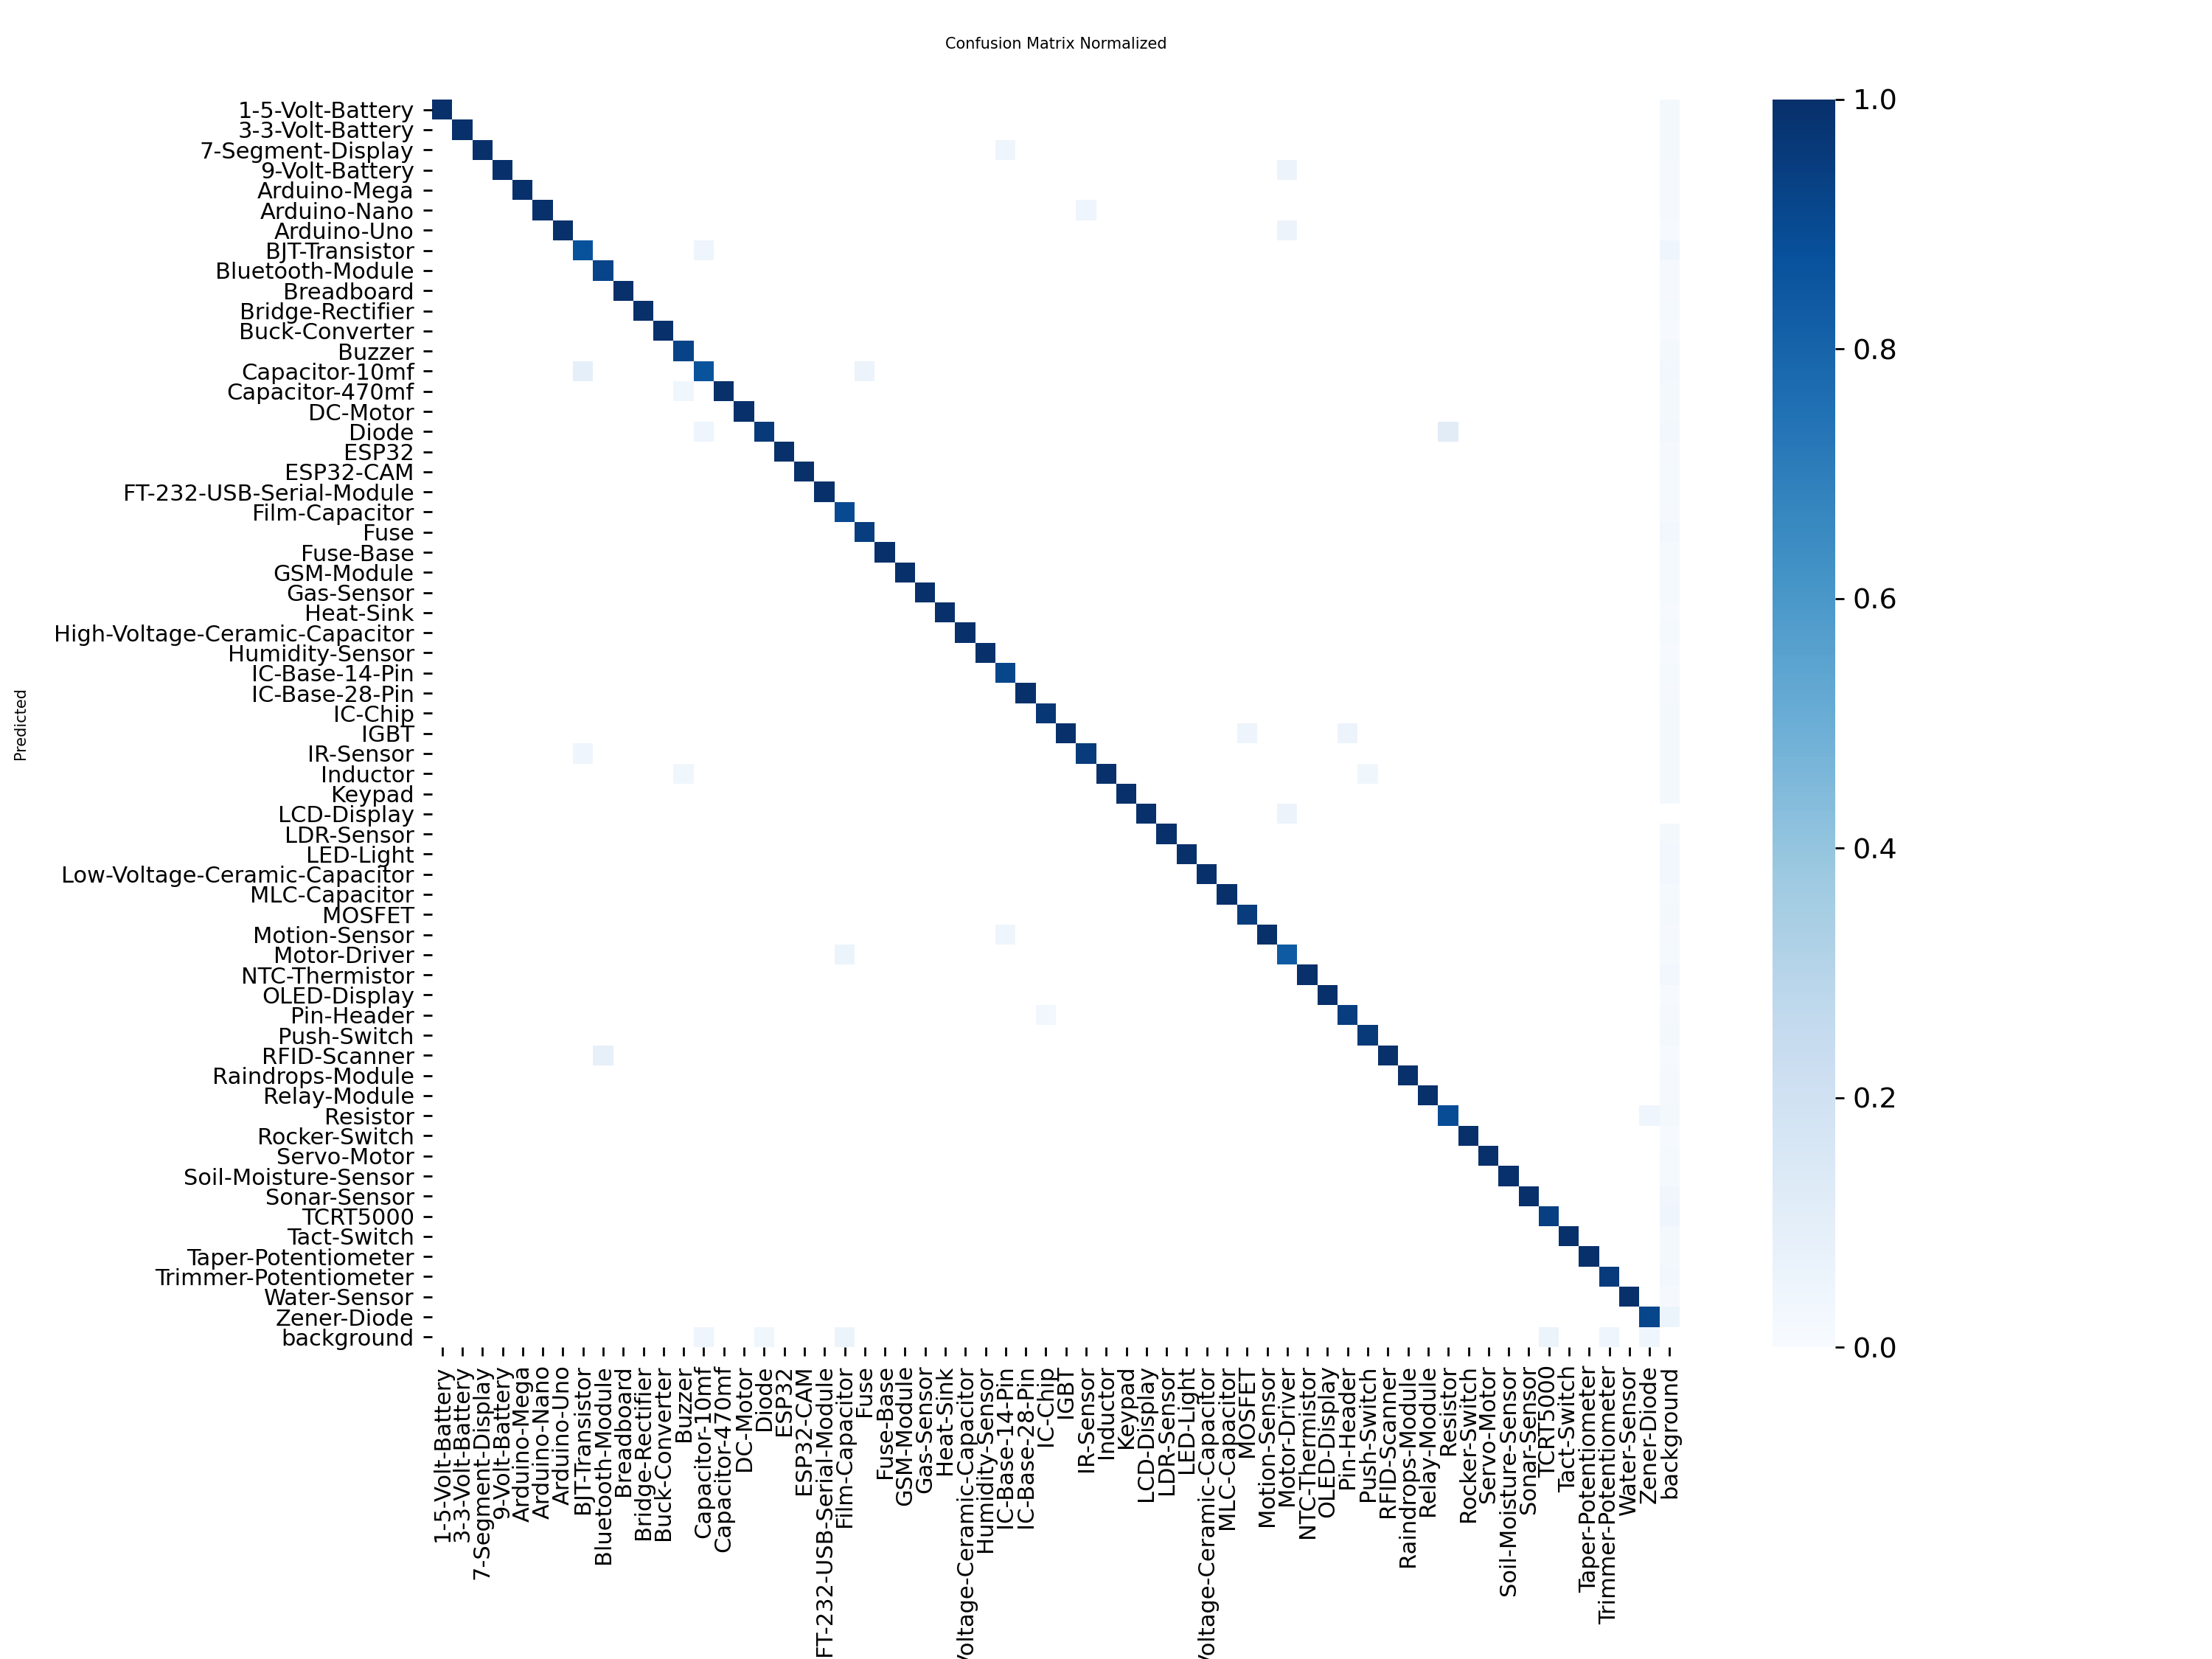

BoxPR_curve.png


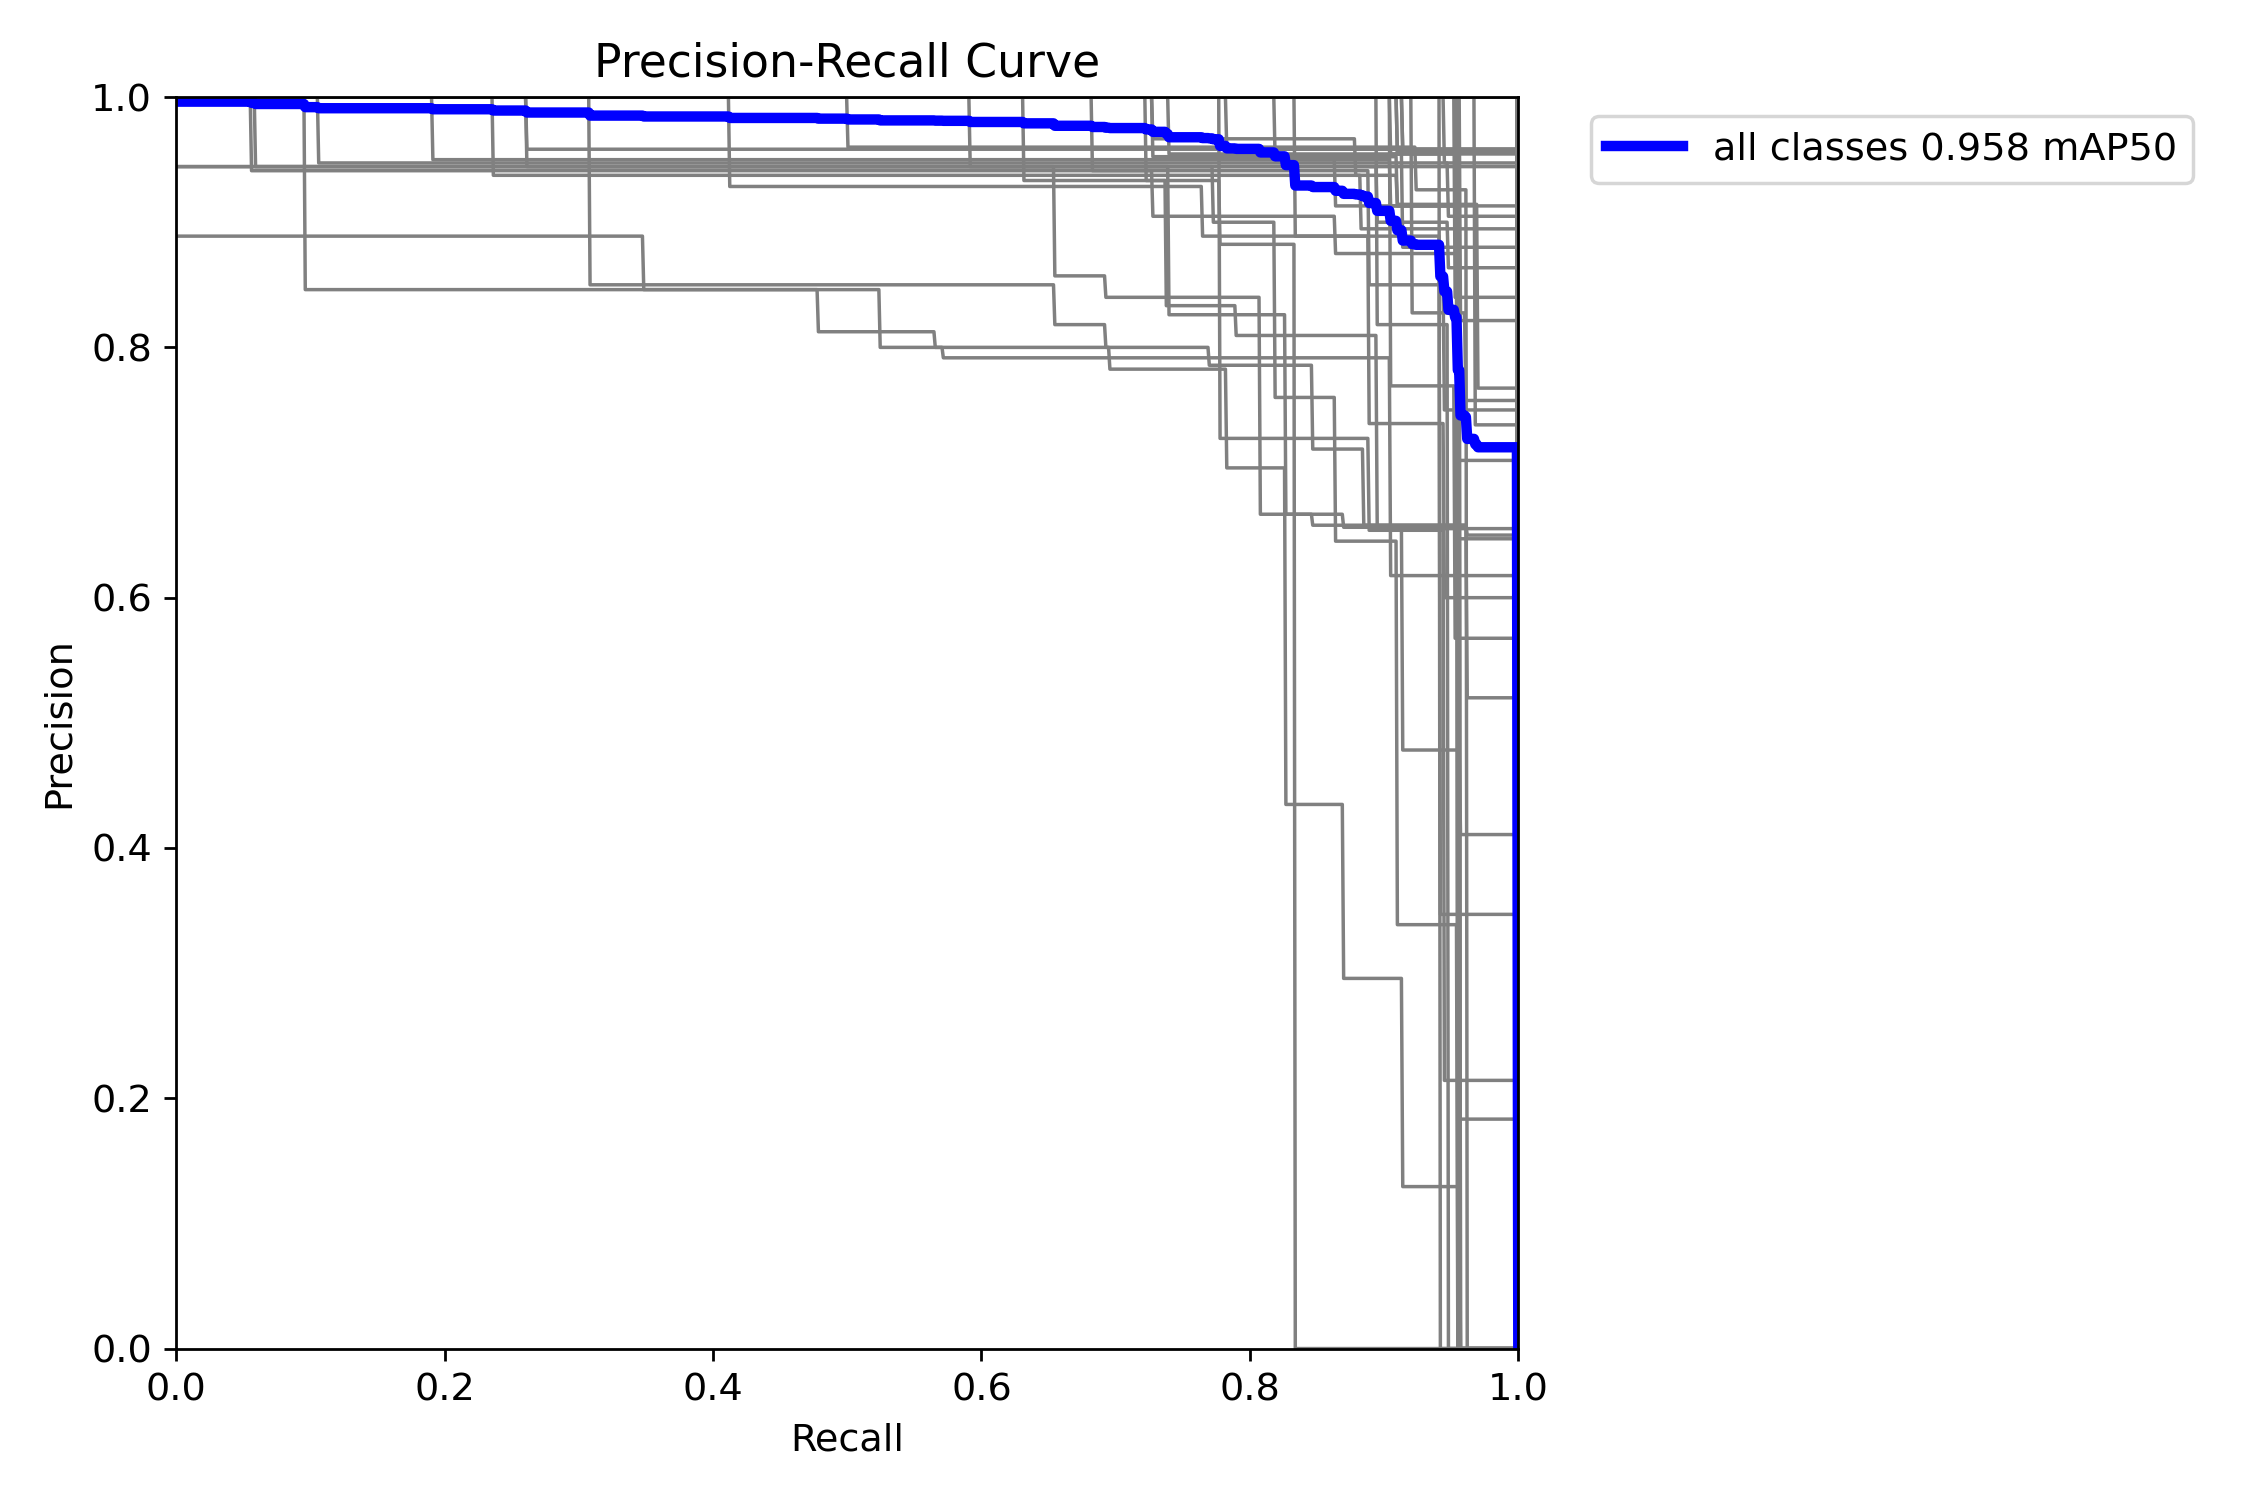

01_10err_IMG_20240220_135838_jpg.rf.35931e86cca3d24d6b43ad1d6a02f89e.jpg


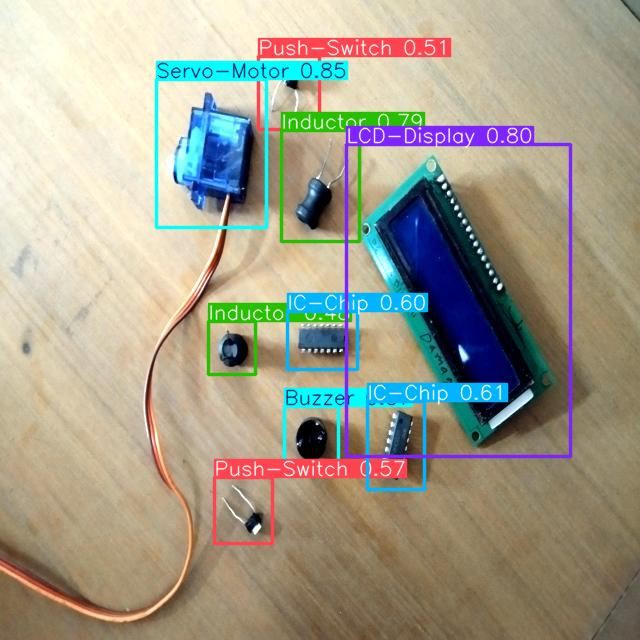

02_9err_IMG_20240309_112630_jpg.rf.e5eff0ac7c21624aecaa052edf7f141a.jpg


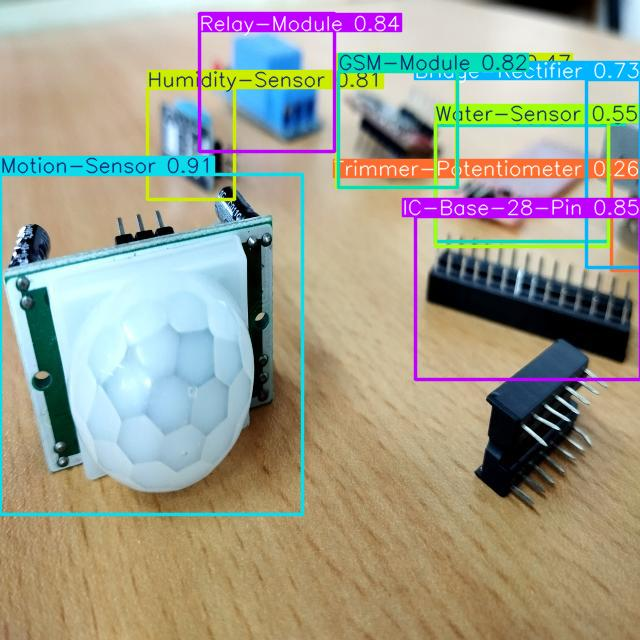

03_8err_IMG20240228133058_jpg.rf.d84239f8b8229ac420f3e3fe95cd2268.jpg


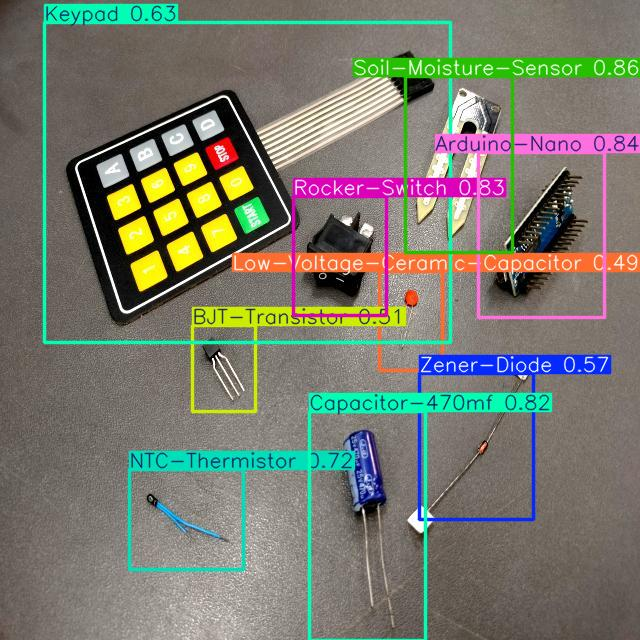

04_8err_IMG20240228142057_jpg.rf.d9104d16f2c9e9efb8be65a0472e58ee.jpg


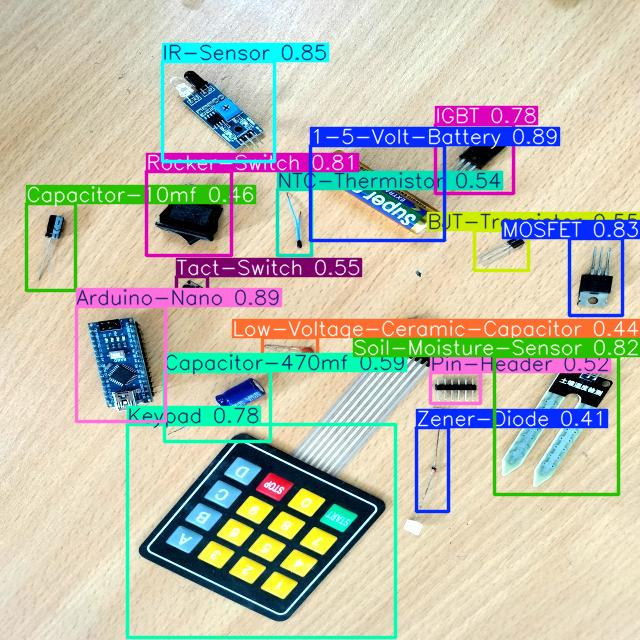

05_7err_IMG_20240220_134436_jpg.rf.fbff527592fe8b19bab9b6680e0afe1c.jpg


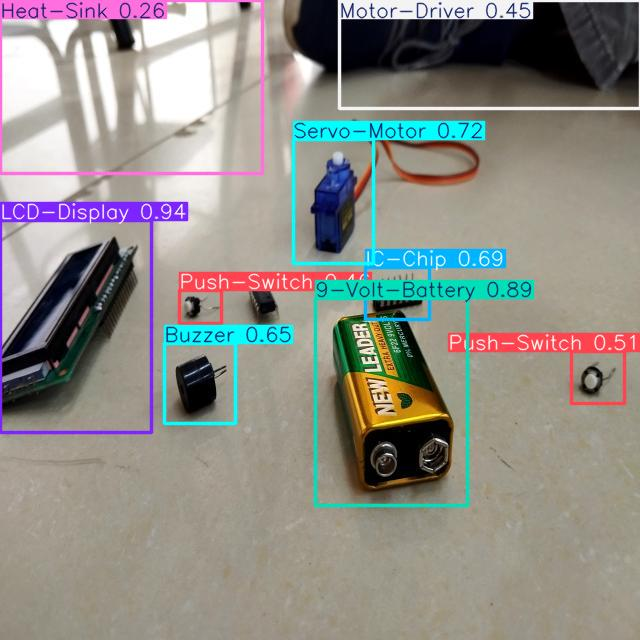

06_5err_IMG20240219120325_jpg.rf.5473ac4d4e57b2a0d616aca88ec6bf47.jpg


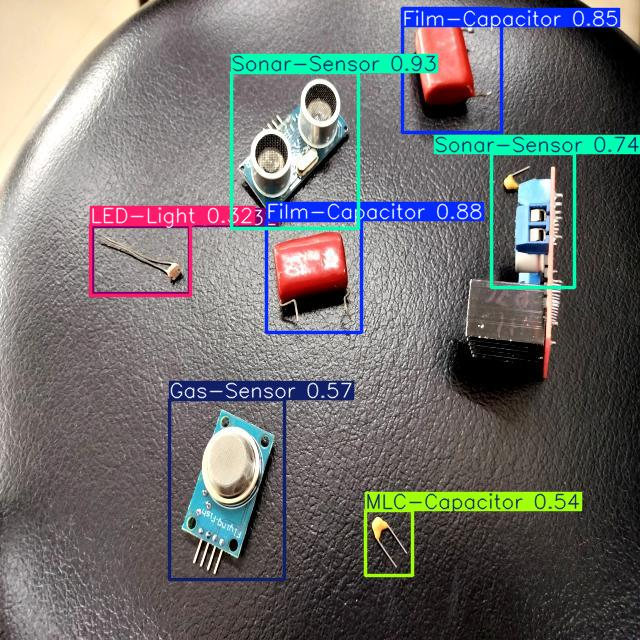

In [ ]:
import pandas as pd
from IPython.display import Image, display

OUT = Path("/kaggle/working/eval/test_v2")
display(pd.read_csv(OUT / "confusions.csv").head(20))
for f in list(OUT.glob("confusion_matrix_normalized.png")) + list(OUT.glob("*PR_curve.png")):
    print(f.name); display(Image(filename=str(f), width=1000))
for f in sorted((OUT / "failures").glob("*"))[:6]:
    print(f.name); display(Image(filename=str(f), width=500))

## 4. Export to LiteRT (float32 and w8a32) and check accuracy

In [ ]:
%%writefile /kaggle/working/export_models.py
"""
CircuitCoach AI - export the trained model for phones (LiteRT .tflite) and check
that the exported files keep their accuracy.

Exports two LiteRT files:
  float32 : full-accuracy reference           -> circuitcoach-yolo26n.tflite
  w8a32   : int8 weights, float activations,   -> circuitcoach-yolo26n_w8a32.tflite
            about 1/4 of the size, no calibration data needed

Then evaluates PyTorch, float32 and w8a32 on the same split and picks the file to ship:
  ship w8a32 if it loses <= --max-drop mAP50 points against float32, otherwise float32.
  float32 itself should be within --max-drop points of PyTorch, or the export is broken.

Usage:
  python export_models.py --weights best.pt --data data.yaml --split test --out release
"""

import argparse
import json
import shutil
from pathlib import Path

from ultralytics import YOLO

STEM = "circuitcoach-yolo26n"


def evaluate(weights, data, split, imgsz, out, tag, device):
    m = YOLO(str(weights), task="detect").val(
        data=data, split=split, imgsz=imgsz, batch=1 if str(weights).endswith(".tflite") else 32,
        device=device, plots=False, verbose=False,
        project=str(out / "val"), name=tag, exist_ok=True,
    )
    return {
        "file": Path(weights).name,
        "size_MB": round(Path(weights).stat().st_size / 1e6, 2),
        "precision": round(float(m.box.mp), 4),
        "recall": round(float(m.box.mr), 4),
        "mAP50": round(float(m.box.map50), 4),
        "mAP50_95": round(float(m.box.map), 4),
        "inference_ms": round(float(m.speed["inference"]), 2),
        "device": device,
    }


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--weights", required=True, help="trained best.pt")
    ap.add_argument("--data", required=True)
    ap.add_argument("--split", default="test")
    ap.add_argument("--out", type=Path, default=Path("/kaggle/working/release"))
    ap.add_argument("--imgsz", type=int, default=640)
    ap.add_argument("--max-drop", type=float, default=2.0, help="allowed mAP50 drop, in points")
    args = ap.parse_args()

    args.out.mkdir(parents=True, exist_ok=True)
    pt = args.out / f"{STEM}.pt"
    shutil.copy2(args.weights, pt)  # exports are written next to this file

    print("[export] LiteRT float32 ...")
    f32 = Path(YOLO(str(pt)).export(format="litert", imgsz=args.imgsz))
    print("[export] LiteRT w8a32 ...")
    w8 = Path(YOLO(str(pt)).export(format="litert", imgsz=args.imgsz, quantize="w8a32"))

    # keep the .tflite files at the top of the release folder with clear names
    final = {}
    for tag, f in [("float32", f32), ("w8a32", w8)]:
        name = f"{STEM}.tflite" if tag == "float32" else f"{STEM}_w8a32.tflite"
        dst = args.out / name
        if f.resolve() != dst.resolve():
            shutil.copy2(f, dst)
        final[tag] = dst

    print(f"[eval] comparing formats on the {args.split} split (tflite runs on CPU) ...")
    rows = {
        "pytorch": evaluate(pt, args.data, args.split, args.imgsz, args.out, "pytorch", 0),
        "float32": evaluate(final["float32"], args.data, args.split, args.imgsz, args.out,
                            "float32", "cpu"),
        "w8a32": evaluate(final["w8a32"], args.data, args.split, args.imgsz, args.out,
                          "w8a32", "cpu"),
    }
    base = rows["pytorch"]["mAP50"]
    for r in rows.values():
        r["drop_vs_pytorch_points"] = round((base - r["mAP50"]) * 100, 2)

    export_ok = rows["float32"]["drop_vs_pytorch_points"] <= args.max_drop
    w8_drop = round((rows["float32"]["mAP50"] - rows["w8a32"]["mAP50"]) * 100, 2)
    ship = "w8a32" if w8_drop <= args.max_drop else "float32"

    report = {"split": args.split, "max_drop_points": args.max_drop, "formats": rows,
              "float32_export_ok": export_ok, "w8a32_drop_vs_float32_points": w8_drop,
              "ship": ship, "ship_file": final[ship].name}
    (args.out / "export_report.json").write_text(json.dumps(report, indent=2))

    print(f"\n{'format':8s} {'size_MB':>8s} {'mAP50':>7s} {'mAP50-95':>9s} "
          f"{'drop(pts)':>10s} {'infer_ms':>9s}  device")
    for tag, r in rows.items():
        print(f"{tag:8s} {r['size_MB']:8.2f} {r['mAP50']:7.3f} {r['mAP50_95']:9.3f} "
              f"{r['drop_vs_pytorch_points']:10.2f} {r['inference_ms']:9.1f}  {r['device']}")
    print(f"\nfloat32 export check: {'OK' if export_ok else 'FAILED - drop too large, re-export'}")
    print(f"w8a32 vs float32: -{w8_drop} mAP50 points")
    print(f"Ship: {ship}  ->  {final[ship].name}")
    print(f"Release folder: {args.out}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/export_models.py


In [ ]:
!python /kaggle/working/export_models.py --weights "{WEIGHTS}" --data "{DATA}" --split test --out /kaggle/working/release

[export] LiteRT float32 ...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,404,315 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from '/kaggle/working/release/circuitcoach-yolo26n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 65, 8400) (5.3 MB)
requirements: Ultralytics requirements ['litert-torch>=0.10.0', 'ai-edge-litert>=2.3.0'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 86 packages in 585ms
Prepared 16 packages in 1.04s
Uninstalled 4 packages in 61ms
Installed 16 packages in 33ms
 + ai-edge-litert==2.3.0
 + ai-edge-quantizer==0.10.1
 - anyio==4.15.1
 + anyio==4.14.2
 + backports-strenum==1.3.1
 + fire==0.7.1
 - immutabledict==4.3.1
 + immutabledict==4.2.1
 + jaxtyping==0.3.11
 + litert-convert

### Box-by-box check: PyTorch vs float32 LiteRT at confidence 0.4

In [ ]:
import numpy as np
from pathlib import Path
from ultralytics import YOLO

REL = Path("/kaggle/working/release")
imgs = sorted((Path(DATA).parent / "test/images").glob("*"))[:25]
pt = YOLO(str(REL / "circuitcoach-yolo26n.pt"))
tf = YOLO(str(REL / "circuitcoach-yolo26n.tflite"), task="detect")

def iou(a, b):
    x0 = np.maximum(a[:, None, 0], b[None, :, 0]); y0 = np.maximum(a[:, None, 1], b[None, :, 1])
    x1 = np.minimum(a[:, None, 2], b[None, :, 2]); y1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

ious, diffs, n_pt, n_tf = [], [], 0, 0
for im in imgs:
    a = pt.predict(str(im), conf=0.4, verbose=False)[0].boxes
    b = tf.predict(str(im), conf=0.4, verbose=False)[0].boxes
    A, ca = a.xyxy.cpu().numpy(), a.cls.cpu().numpy()
    B, cb = b.xyxy.cpu().numpy(), b.cls.cpu().numpy()
    n_pt += len(A); n_tf += len(B)
    for i in range(len(A)):
        same = np.where(cb == ca[i])[0]
        if len(same) == 0:
            continue
        m = iou(A[i:i+1], B[same])[0]
        ious.append(m.max()); diffs.append(B[same[m.argmax()]] - A[i])

d = np.array(diffs)
print(f"boxes: pytorch={n_pt}  tflite={n_tf}  matched={len(ious)}")
print(f"mean IoU pytorch vs tflite: {np.mean(ious):.3f}   share with IoU>0.9: {np.mean(np.array(ious) > 0.9):.2f}")
print("mean offset x1,y1,x2,y2 (px):    ", d.mean(0).round(1))
print("mean abs offset x1,y1,x2,y2 (px):", np.abs(d).mean(0).round(1))

Loading /kaggle/working/release/circuitcoach-yolo26n.tflite for LiteRT inference...


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


boxes: pytorch=160  tflite=160  matched=160
mean IoU pytorch vs tflite: 1.000   share with IoU>0.9: 1.00
mean offset x1,y1,x2,y2 (px):     [          0           0           0           0]
mean abs offset x1,y1,x2,y2 (px): [          0           0           0           0]


## 5. Publish the model and model card to Hugging Face

In [ ]:
%%writefile /kaggle/working/publish_to_hf.py
"""
CircuitCoach AI - build the release folder + model card and upload it to Hugging Face.

Collects:
  release/  circuitcoach-yolo26n.pt, circuitcoach-yolo26n.tflite (float32),
            circuitcoach-yolo26n_w8a32.tflite, export_report.json
  eval/     metrics.json, per_class.csv, confusions.csv, confusion_matrix_normalized.png
  train run args.yaml, results.csv, results.png
  dataset   audit.json, per_class_counts.csv, data.yaml (class names)
and writes README.md (the model card) from the real numbers.

Usage (Kaggle):
  python publish_to_hf.py --release /kaggle/working/release --eval /kaggle/working/eval/test_v2 \
      --train-run <.../runs/yolo26n_ec61_v2> --dataset-dir <.../ec61_clean> --no-upload   # check first
  python publish_to_hf.py ... (same arguments, without --no-upload)                      # publish
The token is read from the HF_TOKEN environment variable or the Kaggle secret HF_TOKEN.
"""

import argparse
import csv
import json
import os
import shutil
from pathlib import Path

import yaml

REPO_NAME = "circuitcoach-yolo26n"

CITATION = """@article{sayeedi2025electrocom61,
  title   = {ElectroCom61: A multiclass dataset for detection of electronic components},
  author  = {Sayeedi, Md. Faiyaz Abdullah and Osmani, Anas Mohammad Ishfaqul Muktadir and
             Rahman, Taimur and Deepti, Jannatul Ferdous and Rahman, Raiyan and Islam, Salekul},
  journal = {Data in Brief},
  volume  = {59},
  pages   = {111331},
  year    = {2025},
  doi     = {10.1016/j.dib.2025.111331}
}"""

FAILURE_NOTES = [
    "**Classification is reliable:** at confidence 0.25, only {wrong} of {total} test boxes "
    "received the wrong class; most errors are missed parts ({missed}) or extra boxes ({fp}).",
    "**Look-alike small parts cause most errors:** small dark round parts (buzzer, push switch, "
    "inductor) and two-lead parts (Zener diode, diode, resistor, small capacitors).",
    "**Background objects:** in photos with a room or floor behind the parts, the model can draw "
    "low-confidence boxes on furniture or people; the dataset has no component-free images.",
    "**Blur and angle:** out-of-focus parts get overlapping low-confidence boxes, steeply angled "
    "parts are missed, and small parts have the loosest boxes.",
    "**Single-lab data:** all images come from one lab, so accuracy on other desks and lighting "
    "is lower than the numbers below; see the phone-test section.",
]


def get_token():
    tok = os.environ.get("HF_TOKEN")
    if tok:
        return tok
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        raise SystemExit("[error] no HF token: set HF_TOKEN or attach the Kaggle secret")


def read_csv(path):
    with open(path, newline="") as f:
        return list(csv.DictReader(f))


def build_card(owner, m, per_class, export, audit, args_yaml, names):
    fr = m["failure_review"]
    fm = export["formats"]
    ship = export["ship"]
    weakest = sorted(per_class, key=lambda r: float(r["mAP50"]))[:10]
    notes = "\n".join(f"{i}. " + n.format(wrong=fr["wrong_class"], total=fr["true_boxes"],
                                          missed=fr["missed"], fp=fr["false_boxes"])
                      for i, n in enumerate(FAILURE_NOTES, 1))

    def row(r):
        return (f"| {r['class_name']} | {r['boxes']} | {float(r['precision']):.2f} | "
                f"{float(r['recall']):.2f} | {float(r['mAP50']):.3f} | {float(r['mAP50_95']):.3f} |")

    head = "| Class | Test boxes | P | R | mAP50 | mAP50-95 |\n|---|---|---|---|---|---|"
    all_rows = "\n".join(row(r) for r in sorted(per_class, key=lambda r: r["class_name"]))
    weak_rows = "\n".join(row(r) for r in weakest)
    tr = args_yaml

    return f"""---
license: agpl-3.0
library_name: ultralytics
pipeline_tag: object-detection
tags:
  - object-detection
  - yolo
  - yolo26
  - ultralytics
  - litert
  - tflite
  - electronics
  - computer-vision
---

# CircuitCoach AI — YOLO26n electronic component detector

Detects **{len(names)} kinds of electronic and robotics components** (Arduino boards, sensors,
modules, passive parts, switches, displays…) in a photo and returns a box, a class name and a
confidence for each one. It is the detection model behind **CircuitCoach AI**, a learning
assistant that tells beginners what a part is and what it does.

- **Model:** Ultralytics YOLO26n (2.4 M parameters), fine-tuned from COCO-pretrained weights
- **Data:** ElectroCom61 (CC BY 4.0), cleaned and re-split by the author of this model
- **Formats:** PyTorch `.pt`, LiteRT float32 `.tflite`, LiteRT w8a32 `.tflite` (shipped for Android)

> **Safety:** for low-voltage (5 V or less) learning circuits. Not a safety check. Never use on
> mains wiring. The model names parts; it does not check whether a circuit is correct or safe.

## Results on the held-out test split

{fr['true_boxes']} boxes in {m['images']} images that were never used for training or model selection.

| Metric | Value |
|---|---|
| Precision | {m['precision']:.3f} |
| Recall | {m['recall']:.3f} |
| **mAP50** | **{m['mAP50']:.3f}** |
| mAP50-95 | {m['mAP50_95']:.3f} |
| Inference (NVIDIA T4, PyTorch) | {m['speed_ms_per_image']['inference']:.1f} ms / image |

At confidence {fr['conf']} (IoU 0.5): {fr['correct']} of {fr['true_boxes']} parts found with the
right name, {fr['wrong_class']} wrong class, {fr['missed']} missed, {fr['false_boxes']} extra boxes.

**These are in-lab numbers.** Test images come from the same lab as the training images.
Expect lower accuracy on your own desk.

### Phone test (real-world)

*Not measured yet.* A separate set of phone photos taken outside the original lab will be
reported here.

### Weakest classes

{head}
{weak_rows}

<details>
<summary>All {len(per_class)} classes</summary>

{head}
{all_rows}

</details>

### Failure analysis

{notes}

## Files

| File | Format | Size | Test mAP50 | Use |
|---|---|---|---|---|
| `circuitcoach-yolo26n.pt` | PyTorch | {fm['pytorch']['size_MB']} MB | {fm['pytorch']['mAP50']:.3f} | Python, web demo |
| `circuitcoach-yolo26n.tflite` | LiteRT float32 | {fm['float32']['size_MB']} MB | {fm['float32']['mAP50']:.3f} | Full-precision reference |
| `circuitcoach-yolo26n_w8a32.tflite` | LiteRT int8 weights, float activations | {fm['w8a32']['size_MB']} MB | {fm['w8a32']['mAP50']:.3f} | **Shipped in the Android app** |

**Export check:** at confidence 0.4 the float32 LiteRT model returned the same boxes as PyTorch
on 25 test images (160 of 160 boxes matched, mean IoU 1.000). The validator's LiteRT mAP50-95
({fm['float32']['mAP50_95']:.3f} float32 / {fm['w8a32']['mAP50_95']:.3f} w8a32) is lower than
PyTorch's ({fm['pytorch']['mAP50_95']:.3f}); this comes from how very-low-confidence boxes are
handled during validation, not from different detections at working thresholds.
w8a32 loses {export['w8a32_drop_vs_float32_points']} mAP50 points against float32 and is about
{fm['float32']['size_MB'] / max(fm['w8a32']['size_MB'], 0.01):.1f}x smaller, so it is shipped.

Other files: `data.yaml` (class names), `metrics/` (test metrics, per-class results, confusion
matrix, export report), `training/` (training arguments and curves), `dataset/` (cleaning audit).

## How to use

```python
from ultralytics import YOLO
from huggingface_hub import hf_hub_download

path = hf_hub_download("{owner}/{REPO_NAME}", "circuitcoach-yolo26n.pt")
model = YOLO(path)
results = model.predict("my_parts.jpg", conf=0.4)
results[0].show()
```

A confidence of about **0.4** is recommended: it removes most low-confidence boxes on
background objects while keeping confident detections.

## Training data

**ElectroCom61** — {audit['images_written']} images of 61 component classes photographed in the
Electronic Lab Support Room of United International University, Dhaka, with several
smartphones, varied lighting, backgrounds and angles. Images were resized to 640×640 by the
dataset authors, which stretches some of them. Licence: **CC BY 4.0**.

**Changes made for this model** (dataset not redistributed here; the scripts are in the
project repository):
1. Merged the original train/valid/test splits into one pool.
2. Checked every image and label line ({audit['images_scanned']} images scanned; checks: {audit['checks']}).
3. Grouped exact duplicates, near-duplicates (64-bit difference hash, distance ≤ {audit['near_dup_bits']})
   and copies of the same source photo, giving {audit['groups']} groups.
4. Re-split 75/15/10 **by group** and stratified by class, so near-identical photos never sit
   on both sides of the train/test line: {audit['split_images']['train']} train /
   {audit['split_images']['val']} val / {audit['split_images']['test']} test images.
   Every class appears in all three splits.

Because of this grouped re-split, the numbers here are not directly comparable with the
dataset paper's results on its random split.

## Training

| Setting | Value |
|---|---|
| Base model | `yolo26n.pt` (pretrained) |
| Image size | {tr.get('imgsz')} |
| Epochs | {tr.get('epochs')} (early stopping off; best epoch selected on validation) |
| Batch size | {tr.get('batch')} |
| Optimizer | {tr.get('optimizer')} (Ultralytics automatic choice) |
| Extra augmentation | rotation ±{tr.get('degrees')}°, vertical flip p={tr.get('flipud')}, plus Ultralytics defaults |
| Seed | {tr.get('seed')}, deterministic={tr.get('deterministic')} |
| Hardware | Kaggle, 1× NVIDIA Tesla T4 |
| Ultralytics | 8.4.215 |

## Limitations

- Trained on photos from a single lab; accuracy drops on unfamiliar backgrounds and lighting.
- Cannot read component values (resistor colour bands, capacitor ratings) or exact model numbers.
- Cannot tell genuine boards from clones.
- Look-alike parts (diode vs Zener diode, push vs tact switch, small capacitors) can be confused.
- Does not trace wires or verify circuits.

## Licence and credit

- **Model weights:** AGPL-3.0 (models trained with Ultralytics code fall under AGPL-3.0).
- **Dataset:** ElectroCom61 by Sayeedi et al., CC BY 4.0, used with the changes listed above.
  Original data: https://data.mendeley.com/datasets/6scy6h8sjz/2

```bibtex
{CITATION}
```
"""


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--release", type=Path, required=True)
    ap.add_argument("--eval", type=Path, required=True)
    ap.add_argument("--train-run", type=Path, required=True)
    ap.add_argument("--dataset-dir", type=Path, required=True)
    ap.add_argument("--stage", type=Path, default=Path("/kaggle/working/hf_release"))
    ap.add_argument("--owner", default=None, help="HF username (default: read from the token)")
    ap.add_argument("--no-upload", action="store_true", help="build the folder only")
    args = ap.parse_args()

    token = None if (args.no_upload and args.owner) else get_token()
    owner = args.owner
    if owner is None:
        from huggingface_hub import whoami
        owner = whoami(token=token)["name"]
    repo_id = f"{owner}/{REPO_NAME}"

    if args.stage.exists():
        shutil.rmtree(args.stage)
    for sub in ["metrics", "training", "dataset"]:
        (args.stage / sub).mkdir(parents=True)

    def put(src, dst, required=True):
        src = Path(src)
        if src.exists():
            shutil.copy2(src, args.stage / dst)
        elif required:
            raise SystemExit(f"[error] missing required file: {src}")
        else:
            print(f"[skip] not found: {src}")

    for f in ["circuitcoach-yolo26n.pt", "circuitcoach-yolo26n.tflite",
              "circuitcoach-yolo26n_w8a32.tflite"]:
        put(args.release / f, f)
    put(args.release / "export_report.json", "metrics/export_report.json")
    for f in ["metrics.json", "per_class.csv", "confusions.csv"]:
        put(args.eval / f, f"metrics/{f}")
    put(args.eval / "confusion_matrix_normalized.png", "metrics/confusion_matrix_normalized.png", False)
    put(args.train_run / "args.yaml", "training/args.yaml")
    put(args.train_run / "results.csv", "training/results.csv")
    put(args.train_run / "results.png", "training/results.png", False)
    put(args.dataset_dir / "audit.json", "dataset/audit.json")
    put(args.dataset_dir / "per_class_counts.csv", "dataset/per_class_counts.csv")

    meta = yaml.safe_load((args.dataset_dir / "data.yaml").read_text())
    names = meta["names"]
    names = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
    (args.stage / "data.yaml").write_text(
        yaml.safe_dump({"nc": len(names), "names": {i: n for i, n in enumerate(names)}},
                       sort_keys=False))

    card = build_card(
        owner,
        json.loads((args.eval / "metrics.json").read_text()),
        read_csv(args.eval / "per_class.csv"),
        json.loads((args.release / "export_report.json").read_text()),
        json.loads((args.dataset_dir / "audit.json").read_text()),
        yaml.safe_load((args.train_run / "args.yaml").read_text()),
        names,
    )
    (args.stage / "README.md").write_text(card)

    print(f"[stage] built {args.stage}:")
    for p in sorted(args.stage.rglob("*")):
        if p.is_file():
            print(f"   {p.relative_to(args.stage)}  ({p.stat().st_size / 1e6:.2f} MB)")

    if args.no_upload:
        print(f"[stage] --no-upload: nothing sent. Review {args.stage / 'README.md'}, then run "
              f"again without --no-upload to publish to {repo_id}")
        return

    from huggingface_hub import HfApi
    api = HfApi(token=token)
    api.create_repo(repo_id, repo_type="model", private=False, exist_ok=True)
    api.upload_folder(folder_path=str(args.stage), repo_id=repo_id, repo_type="model",
                      commit_message="CircuitCoach YOLO26n v2: weights, LiteRT exports, metrics, model card")
    print(f"[done] published: https://huggingface.co/{repo_id}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/publish_to_hf.py


In [ ]:
import os
from pathlib import Path
from kaggle_secrets import UserSecretsClient

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")  # never printed

TRAIN_RUN = Path(WEIGHTS).parent.parent          # .../runs/yolo26n_ec61_v2
DATASET_DIR = Path(DATA).parent                   # the rebuilt clean dataset
EVAL_DIR = Path("/kaggle/working/eval/test_v2")
RELEASE = Path("/kaggle/working/release")
for p in [TRAIN_RUN, DATASET_DIR, EVAL_DIR, RELEASE]:
    print(p, "OK" if p.exists() else "MISSING")

!python /kaggle/working/publish_to_hf.py --release "{RELEASE}" --eval "{EVAL_DIR}" --train-run "{TRAIN_RUN}" --dataset-dir "{DATASET_DIR}" --no-upload

/kaggle/input/notebooks/mohamedjatheel/circuitcoach-training/runs/yolo26n_ec61_v2 OK
/kaggle/working/ec61_clean OK
/kaggle/working/eval/test_v2 OK
/kaggle/working/release OK
[stage] built /kaggle/working/hf_release:
   README.md  (0.01 MB)
   circuitcoach-yolo26n.pt  (5.52 MB)
   circuitcoach-yolo26n.tflite  (9.95 MB)
   circuitcoach-yolo26n_w8a32.tflite  (2.87 MB)
   data.yaml  (0.00 MB)
   dataset/audit.json  (0.00 MB)
   dataset/per_class_counts.csv  (0.00 MB)
   metrics/confusion_matrix_normalized.png  (0.57 MB)
   metrics/confusions.csv  (0.00 MB)
   metrics/export_report.json  (0.00 MB)
   metrics/metrics.json  (0.00 MB)
   metrics/per_class.csv  (0.00 MB)
   training/args.yaml  (0.00 MB)
   training/results.csv  (0.01 MB)
   training/results.png  (0.25 MB)
[stage] --no-upload: nothing sent. Review /kaggle/working/hf_release/README.md, then run again without --no-upload to publish to JatheelMHD/circuitcoach-yolo26n


In [ ]:
from IPython.display import Markdown, display
display(Markdown(open("/kaggle/working/hf_release/README.md").read()))

---
license: agpl-3.0
library_name: ultralytics
pipeline_tag: object-detection
tags:
  - object-detection
  - yolo
  - yolo26
  - ultralytics
  - litert
  - tflite
  - electronics
  - computer-vision
---

# CircuitCoach AI — YOLO26n electronic component detector

Detects **61 kinds of electronic and robotics components** (Arduino boards, sensors,
modules, passive parts, switches, displays…) in a photo and returns a box, a class name and a
confidence for each one. It is the detection model behind **CircuitCoach AI**, a learning
assistant that tells beginners what a part is and what it does.

- **Model:** Ultralytics YOLO26n (2.4 M parameters), fine-tuned from COCO-pretrained weights
- **Data:** ElectroCom61 (CC BY 4.0), cleaned and re-split by the author of this model
- **Formats:** PyTorch `.pt`, LiteRT float32 `.tflite`, LiteRT w8a32 `.tflite` (shipped for Android)

> **Safety:** for low-voltage (5 V or less) learning circuits. Not a safety check. Never use on
> mains wiring. The model names parts; it does not check whether a circuit is correct or safe.

## Results on the held-out test split

1294 boxes in 230 images that were never used for training or model selection.

| Metric | Value |
|---|---|
| Precision | 0.926 |
| Recall | 0.940 |
| **mAP50** | **0.958** |
| mAP50-95 | 0.649 |
| Inference (NVIDIA T4, PyTorch) | 5.2 ms / image |

At confidence 0.25 (IoU 0.5): 1208 of 1294 parts found with the
right name, 14 wrong class, 72 missed, 97 extra boxes.

**These are in-lab numbers.** Test images come from the same lab as the training images.
Expect lower accuracy on your own desk.

### Phone test (real-world)

*Not measured yet.* A separate set of phone photos taken outside the original lab will be
reported here.

### Weakest classes

| Class | Test boxes | P | R | mAP50 | mAP50-95 |
|---|---|---|---|---|---|
| Zener-Diode | 23 | 0.74 | 0.78 | 0.730 | 0.371 |
| Tact-Switch | 21 | 0.79 | 0.89 | 0.816 | 0.349 |
| Motor-Driver | 18 | 0.88 | 0.78 | 0.825 | 0.658 |
| Push-Switch | 26 | 0.78 | 0.81 | 0.855 | 0.437 |
| Buzzer | 26 | 0.82 | 0.81 | 0.867 | 0.498 |
| BJT-Transistor | 23 | 0.93 | 0.59 | 0.878 | 0.441 |
| Capacitor-10mf | 22 | 0.84 | 0.82 | 0.882 | 0.526 |
| Fuse | 18 | 0.97 | 0.78 | 0.905 | 0.568 |
| Servo-Motor | 17 | 0.89 | 0.92 | 0.917 | 0.633 |
| Keypad | 19 | 0.75 | 0.89 | 0.925 | 0.681 |

<details>
<summary>All 61 classes</summary>

| Class | Test boxes | P | R | mAP50 | mAP50-95 |
|---|---|---|---|---|---|
| 1-5-Volt-Battery | 22 | 0.97 | 1.00 | 0.995 | 0.629 |
| 3-3-Volt-Battery | 21 | 0.96 | 0.95 | 0.989 | 0.729 |
| 7-Segment-Display | 19 | 0.90 | 0.99 | 0.946 | 0.626 |
| 9-Volt-Battery | 17 | 0.92 | 1.00 | 0.943 | 0.712 |
| Arduino-Mega | 18 | 0.95 | 0.99 | 0.992 | 0.868 |
| Arduino-Nano | 19 | 0.86 | 1.00 | 0.933 | 0.661 |
| Arduino-Uno | 20 | 0.98 | 1.00 | 0.995 | 0.867 |
| BJT-Transistor | 23 | 0.93 | 0.59 | 0.878 | 0.441 |
| Bluetooth-Module | 25 | 0.99 | 0.92 | 0.978 | 0.729 |
| Breadboard | 18 | 0.92 | 1.00 | 0.995 | 0.873 |
| Bridge-Rectifier | 22 | 0.95 | 0.94 | 0.979 | 0.749 |
| Buck-Converter | 17 | 1.00 | 0.97 | 0.995 | 0.783 |
| Buzzer | 26 | 0.82 | 0.81 | 0.867 | 0.498 |
| Capacitor-10mf | 22 | 0.84 | 0.82 | 0.882 | 0.526 |
| Capacitor-470mf | 22 | 0.95 | 0.91 | 0.971 | 0.623 |
| DC-Motor | 18 | 0.97 | 1.00 | 0.995 | 0.591 |
| Diode | 26 | 0.89 | 0.96 | 0.945 | 0.572 |
| ESP32 | 19 | 0.98 | 1.00 | 0.995 | 0.790 |
| ESP32-CAM | 19 | 0.97 | 1.00 | 0.995 | 0.741 |
| FT-232-USB-Serial-Module | 17 | 0.97 | 1.00 | 0.995 | 0.706 |
| Film-Capacitor | 19 | 0.91 | 0.89 | 0.936 | 0.691 |
| Fuse | 18 | 0.97 | 0.78 | 0.905 | 0.568 |
| Fuse-Base | 18 | 1.00 | 0.99 | 0.995 | 0.736 |
| GSM-Module | 23 | 0.96 | 0.98 | 0.965 | 0.679 |
| Gas-Sensor | 23 | 0.96 | 0.96 | 0.988 | 0.742 |
| Heat-Sink | 18 | 0.97 | 1.00 | 0.995 | 0.840 |
| High-Voltage-Ceramic-Capacitor | 26 | 0.98 | 1.00 | 0.995 | 0.569 |
| Humidity-Sensor | 23 | 0.88 | 1.00 | 0.992 | 0.748 |
| IC-Base-14-Pin | 23 | 0.95 | 0.90 | 0.942 | 0.615 |
| IC-Base-28-Pin | 22 | 0.97 | 1.00 | 0.995 | 0.745 |
| IC-Chip | 33 | 0.93 | 0.91 | 0.976 | 0.531 |
| IGBT | 21 | 1.00 | 0.86 | 0.991 | 0.619 |
| IR-Sensor | 22 | 0.96 | 0.95 | 0.955 | 0.556 |
| Inductor | 29 | 0.96 | 1.00 | 0.995 | 0.503 |
| Keypad | 19 | 0.75 | 0.89 | 0.925 | 0.681 |
| LCD-Display | 17 | 0.85 | 1.00 | 0.943 | 0.764 |
| LDR-Sensor | 17 | 0.99 | 1.00 | 0.995 | 0.640 |
| LED-Light | 30 | 0.97 | 1.00 | 0.995 | 0.627 |
| Low-Voltage-Ceramic-Capacitor | 21 | 0.82 | 0.90 | 0.966 | 0.480 |
| MLC-Capacitor | 31 | 0.99 | 0.97 | 0.987 | 0.546 |
| MOSFET | 21 | 0.94 | 0.90 | 0.952 | 0.499 |
| Motion-Sensor | 23 | 0.94 | 1.00 | 0.986 | 0.796 |
| Motor-Driver | 18 | 0.88 | 0.78 | 0.825 | 0.658 |
| NTC-Thermistor | 22 | 0.87 | 0.86 | 0.935 | 0.456 |
| OLED-Display | 28 | 0.98 | 1.00 | 0.995 | 0.759 |
| Pin-Header | 18 | 0.88 | 0.83 | 0.954 | 0.578 |
| Push-Switch | 26 | 0.78 | 0.81 | 0.855 | 0.437 |
| RFID-Scanner | 16 | 0.87 | 1.00 | 0.995 | 0.854 |
| Raindrops-Module | 19 | 0.98 | 1.00 | 0.995 | 0.822 |
| Relay-Module | 22 | 0.84 | 1.00 | 0.980 | 0.814 |
| Resistor | 18 | 0.84 | 0.89 | 0.925 | 0.611 |
| Rocker-Switch | 18 | 0.97 | 1.00 | 0.995 | 0.604 |
| Servo-Motor | 17 | 0.89 | 0.92 | 0.917 | 0.633 |
| Soil-Moisture-Sensor | 19 | 1.00 | 0.98 | 0.995 | 0.672 |
| Sonar-Sensor | 22 | 0.93 | 1.00 | 0.991 | 0.742 |
| TCRT5000 | 17 | 0.93 | 0.94 | 0.945 | 0.485 |
| Tact-Switch | 21 | 0.79 | 0.89 | 0.816 | 0.349 |
| Taper-Potentiometer | 18 | 1.00 | 0.99 | 0.995 | 0.502 |
| Trimmer-Potentiometer | 23 | 1.00 | 0.91 | 0.953 | 0.533 |
| Water-Sensor | 22 | 0.94 | 1.00 | 0.995 | 0.808 |
| Zener-Diode | 23 | 0.74 | 0.78 | 0.730 | 0.371 |

</details>

### Failure analysis

1. **Classification is reliable:** at confidence 0.25, only 14 of 1294 test boxes received the wrong class; most errors are missed parts (72) or extra boxes (97).
2. **Look-alike small parts cause most errors:** small dark round parts (buzzer, push switch, inductor) and two-lead parts (Zener diode, diode, resistor, small capacitors).
3. **Background objects:** in photos with a room or floor behind the parts, the model can draw low-confidence boxes on furniture or people; the dataset has no component-free images.
4. **Blur and angle:** out-of-focus parts get overlapping low-confidence boxes, steeply angled parts are missed, and small parts have the loosest boxes.
5. **Single-lab data:** all images come from one lab, so accuracy on other desks and lighting is lower than the numbers below; see the phone-test section.

## Files

| File | Format | Size | Test mAP50 | Use |
|---|---|---|---|---|
| `circuitcoach-yolo26n.pt` | PyTorch | 5.52 MB | 0.958 | Python, web demo |
| `circuitcoach-yolo26n.tflite` | LiteRT float32 | 9.95 MB | 0.945 | Full-precision reference |
| `circuitcoach-yolo26n_w8a32.tflite` | LiteRT int8 weights, float activations | 2.87 MB | 0.944 | **Shipped in the Android app** |

**Export check:** at confidence 0.4 the float32 LiteRT model returned the same boxes as PyTorch
on 25 test images (160 of 160 boxes matched, mean IoU 1.000). The validator's LiteRT mAP50-95
(0.553 float32 / 0.557 w8a32) is lower than
PyTorch's (0.649); this comes from how very-low-confidence boxes are
handled during validation, not from different detections at working thresholds.
w8a32 loses 0.07 mAP50 points against float32 and is about
3.5x smaller, so it is shipped.

Other files: `data.yaml` (class names), `metrics/` (test metrics, per-class results, confusion
matrix, export report), `training/` (training arguments and curves), `dataset/` (cleaning audit).

## How to use

```python
from ultralytics import YOLO
from huggingface_hub import hf_hub_download

path = hf_hub_download("JatheelMHD/circuitcoach-yolo26n", "circuitcoach-yolo26n.pt")
model = YOLO(path)
results = model.predict("my_parts.jpg", conf=0.4)
results[0].show()
```

A confidence of about **0.4** is recommended: it removes most low-confidence boxes on
background objects while keeping confident detections.

## Training data

**ElectroCom61** — 2121 images of 61 component classes photographed in the
Electronic Lab Support Room of United International University, Dhaka, with several
smartphones, varied lighting, backgrounds and angles. Images were resized to 640×640 by the
dataset authors, which stretches some of them. Licence: **CC BY 4.0**.

**Changes made for this model** (dataset not redistributed here; the scripts are in the
project repository):
1. Merged the original train/valid/test splits into one pool.
2. Checked every image and label line (2121 images scanned; checks: {'near_duplicate_pairs': 17}).
3. Grouped exact duplicates, near-duplicates (64-bit difference hash, distance ≤ 6)
   and copies of the same source photo, giving 2104 groups.
4. Re-split 75/15/10 **by group** and stratified by class, so near-identical photos never sit
   on both sides of the train/test line: 1569 train /
   322 val / 230 test images.
   Every class appears in all three splits.

Because of this grouped re-split, the numbers here are not directly comparable with the
dataset paper's results on its random split.

## Training

| Setting | Value |
|---|---|
| Base model | `yolo26n.pt` (pretrained) |
| Image size | 640 |
| Epochs | 100 (early stopping off; best epoch selected on validation) |
| Batch size | 32 |
| Optimizer | auto (Ultralytics automatic choice) |
| Extra augmentation | rotation ±10°, vertical flip p=0.5, plus Ultralytics defaults |
| Seed | 0, deterministic=True |
| Hardware | Kaggle, 1× NVIDIA Tesla T4 |
| Ultralytics | 8.4.215 |

## Limitations

- Trained on photos from a single lab; accuracy drops on unfamiliar backgrounds and lighting.
- Cannot read component values (resistor colour bands, capacitor ratings) or exact model numbers.
- Cannot tell genuine boards from clones.
- Look-alike parts (diode vs Zener diode, push vs tact switch, small capacitors) can be confused.
- Does not trace wires or verify circuits.

## Licence and credit

- **Model weights:** AGPL-3.0 (models trained with Ultralytics code fall under AGPL-3.0).
- **Dataset:** ElectroCom61 by Sayeedi et al., CC BY 4.0, used with the changes listed above.
  Original data: https://data.mendeley.com/datasets/6scy6h8sjz/2

```bibtex
@article{sayeedi2025electrocom61,
  title   = {ElectroCom61: A multiclass dataset for detection of electronic components},
  author  = {Sayeedi, Md. Faiyaz Abdullah and Osmani, Anas Mohammad Ishfaqul Muktadir and
             Rahman, Taimur and Deepti, Jannatul Ferdous and Rahman, Raiyan and Islam, Salekul},
  journal = {Data in Brief},
  volume  = {59},
  pages   = {111331},
  year    = {2025},
  doi     = {10.1016/j.dib.2025.111331}
}
```


In [ ]:
!python /kaggle/working/publish_to_hf.py --release "{RELEASE}" --eval "{EVAL_DIR}" --train-run "{TRAIN_RUN}" --dataset-dir "{DATASET_DIR}"

[stage] built /kaggle/working/hf_release:
   README.md  (0.01 MB)
   circuitcoach-yolo26n.pt  (5.52 MB)
   circuitcoach-yolo26n.tflite  (9.95 MB)
   circuitcoach-yolo26n_w8a32.tflite  (2.87 MB)
   data.yaml  (0.00 MB)
   dataset/audit.json  (0.00 MB)
   dataset/per_class_counts.csv  (0.00 MB)
   metrics/confusion_matrix_normalized.png  (0.57 MB)
   metrics/confusions.csv  (0.00 MB)
   metrics/export_report.json  (0.00 MB)
   metrics/metrics.json  (0.00 MB)
   metrics/per_class.csv  (0.00 MB)
   training/args.yaml  (0.00 MB)
   training/results.csv  (0.01 MB)
   training/results.png  (0.25 MB)
Found 15 files to upload
  Preparing   ████████████████████  15 / 15 ✓
  Uploading   ████████████████████  5 / 5 files ✓
  Validating  ░░░░░░░░░░░░░░░░░░░░  0%
  Committing  ░░░░░░░░░░░░░░░░░░░░  0 / 15
  Preparing   ████████████████████  15 / 15 ✓
  Uploading   ████████████████████  5 / 5 files ✓
  Validating  ████████████████████  100%
  Committing  ████████████████████  15 / 15 ✓
No files have 

## 6. Export ONNX for the in-browser web demo

In [ ]:
%%writefile /kaggle/working/export_onnx.py
"""
CircuitCoach AI - export the model to ONNX for the in-browser web demo, check it, and
(optionally) upload it to the Hugging Face model repo.

The ONNX file embeds NMS, so its output is (1, 300, 6):
  [x1, y1, x2, y2, confidence, class_id] in 640x640 input pixels.
The browser only has to filter by confidence and undo the letterbox.

Checks:
  1. test-split mAP of the ONNX model vs PyTorch
  2. box-by-box agreement with PyTorch at conf 0.4 on 25 test images

Usage (Kaggle):
  python export_onnx.py --weights best.pt --data data.yaml --out /kaggle/working/onnx           # check only
  python export_onnx.py --weights best.pt --data data.yaml --out /kaggle/working/onnx --upload  # + upload
"""

import argparse
import json
import os
import shutil
from pathlib import Path

import numpy as np
from ultralytics import YOLO

REPO_NAME = "circuitcoach-yolo26n"
ONNX_NAME = "circuitcoach-yolo26n.onnx"


def iou(a, b):
    x0 = np.maximum(a[:, None, 0], b[None, :, 0]); y0 = np.maximum(a[:, None, 1], b[None, :, 1])
    x1 = np.minimum(a[:, None, 2], b[None, :, 2]); y1 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x1 - x0, 0, None) * np.clip(y1 - y0, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--weights", required=True)
    ap.add_argument("--data", required=True)
    ap.add_argument("--out", type=Path, default=Path("/kaggle/working/onnx"))
    ap.add_argument("--upload", action="store_true")
    args = ap.parse_args()

    args.out.mkdir(parents=True, exist_ok=True)
    pt = args.out / "circuitcoach-yolo26n.pt"
    shutil.copy2(args.weights, pt)

    print("[export] ONNX with embedded NMS ...")
    onnx = Path(YOLO(str(pt)).export(format="onnx", imgsz=640, nms=True, simplify=True))
    if onnx.name != ONNX_NAME:
        onnx = Path(shutil.move(onnx, args.out / ONNX_NAME))

    import onnxruntime as ort
    sess = ort.InferenceSession(str(onnx), providers=["CPUExecutionProvider"])
    io = {"inputs": [(i.name, i.shape) for i in sess.get_inputs()],
          "outputs": [(o.name, o.shape) for o in sess.get_outputs()]}
    print("[onnx] inputs:", io["inputs"], "| outputs:", io["outputs"])

    print("[eval] test split: PyTorch vs ONNX ...")
    res = {}
    for tag, w, kw in [("pytorch", pt, {"batch": 32, "device": 0}),
                       ("onnx", onnx, {"batch": 1, "device": "cpu"})]:
        m = YOLO(str(w), task="detect").val(data=args.data, split="test", imgsz=640, plots=False,
                                            verbose=False, project=str(args.out / "val"), name=tag,
                                            exist_ok=True, **kw)
        res[tag] = {"mAP50": round(float(m.box.map50), 4), "mAP50_95": round(float(m.box.map), 4),
                    "precision": round(float(m.box.mp), 4), "recall": round(float(m.box.mr), 4)}

    print("[check] box agreement at conf 0.4 on 25 test images ...")
    root = Path(args.data).parent
    imgs = sorted((root / "test/images").glob("*"))[:25]
    m_pt, m_ox = YOLO(str(pt)), YOLO(str(onnx), task="detect")
    ious, n_pt, n_ox = [], 0, 0
    for im in imgs:
        a = m_pt.predict(str(im), conf=0.4, verbose=False)[0].boxes
        b = m_ox.predict(str(im), conf=0.4, verbose=False)[0].boxes
        A, ca = a.xyxy.cpu().numpy(), a.cls.cpu().numpy()
        B, cb = b.xyxy.cpu().numpy(), b.cls.cpu().numpy()
        n_pt += len(A); n_ox += len(B)
        for i in range(len(A)):
            same = np.where(cb == ca[i])[0]
            if len(same):
                ious.append(float(iou(A[i:i + 1], B[same])[0].max()))
    agree = {"boxes_pytorch": n_pt, "boxes_onnx": n_ox, "matched": len(ious),
             "mean_iou": round(float(np.mean(ious)), 4) if ious else None}

    report = {"file": ONNX_NAME, "size_MB": round(onnx.stat().st_size / 1e6, 2), "io": io,
              "test": res, "agreement_conf0.4": agree}
    (args.out / "onnx_report.json").write_text(json.dumps(report, indent=2))

    print(f"\n{'format':8s} {'mAP50':>7s} {'mAP50-95':>9s} {'P':>6s} {'R':>6s}")
    for tag, r in res.items():
        print(f"{tag:8s} {r['mAP50']:7.3f} {r['mAP50_95']:9.3f} {r['precision']:6.3f} {r['recall']:6.3f}")
    print(f"\nboxes at conf 0.4: pytorch={n_pt} onnx={n_ox} matched={len(ious)} "
          f"mean IoU={agree['mean_iou']}")
    print(f"ONNX file: {onnx} ({report['size_MB']} MB)")

    if args.upload:
        from huggingface_hub import HfApi, whoami
        token = os.environ.get("HF_TOKEN")
        if not token:
            from kaggle_secrets import UserSecretsClient
            token = UserSecretsClient().get_secret("HF_TOKEN")
        repo_id = f"{whoami(token=token)['name']}/{REPO_NAME}"
        api = HfApi(token=token)
        api.upload_file(path_or_fileobj=str(onnx), path_in_repo=ONNX_NAME, repo_id=repo_id,
                        commit_message="Add ONNX export with embedded NMS for the web demo")
        api.upload_file(path_or_fileobj=str(args.out / "onnx_report.json"),
                        path_in_repo="metrics/onnx_report.json", repo_id=repo_id,
                        commit_message="Add ONNX export check")
        print(f"[done] uploaded: https://huggingface.co/{repo_id}/blob/main/{ONNX_NAME}")


if __name__ == "__main__":
    main()


Writing /kaggle/working/export_onnx.py


In [ ]:
!python /kaggle/working/export_onnx.py --weights "{WEIGHTS}" --data "{DATA}" --out /kaggle/working/onnx

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
[export] ONNX with embedded NMS ...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,404,315 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from '/kaggle/working/onnx/circuitcoach-yolo26n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.3 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.6s, saved as '/kaggle/working/onnx/circuitcoach-yolo26n.onnx' (9.5 MB)

Export complete (7.2s)

Upload the ONNX file to the model repo:

In [ ]:
import os
from kaggle_secrets import UserSecretsClient
os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
!python /kaggle/working/export_onnx.py --weights "{WEIGHTS}" --data "{DATA}" --out /kaggle/working/onnx --upload


[export] ONNX with embedded NMS ...
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 121 layers, 2,404,315 parameters, 0 gradients, 5.5 GFLOPs

PyTorch: starting from '/kaggle/working/onnx/circuitcoach-yolo26n.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 300, 6) (5.3 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.1s, saved as '/kaggle/working/onnx/circuitcoach-yolo26n.onnx' (9.5 MB)

Export complete (3.6s)
Results saved to /kaggle/working/onnx/circuitcoach-yolo26n.onnx
Predict:         yolo predict task=detect model=/kaggle/working/onnx/circuitcoach-yolo26n.onnx imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/onnx/circuitcoach-yolo26n.onnx imgsz=640 data=/kaggle/working/ec61_clean/data.yaml 
Visualize:       https://netron.app
[onnx] inputs: [('images', [1, 3, 640, 640])] | outputs: [('output0', [1, 300, 6])